# Exercise: From Energy to Speed in a 2D Gas (Solutions)

**Background:**
Consider a classical ideal gas confined to two dimensions. According to Boltzmann statistics, the dimensionless kinetic energy $x$ of a single particle follows an exponential probability density function (PDF) for $x \geq 0$:
$$f(x) = e^{-x}$$

We want to determine the statistical properties of the particle's dimensionless speed, defined as:
$$y = \sqrt{x}$$

In this exercise, we derive the exact statistical properties of the speed analytically and verify the results using Monte Carlo sampling.

## Part 1: Analytical Derivations

### 1. The PDF $g(y)$
We use the transformation of variables formula: $g(y) = f(x(y)) \left| \frac{dx}{dy} \right|$.

* The inverse function is $x = y^2$.
* The derivative (Jacobian) is $\frac{dx}{dy} = 2y$.
* Substituting these into the formula:
  $$g(y) = e^{-y^2} |2y|$$
Since speed $y \geq 0$, we can drop the absolute value:
**$$g(y) = 2y e^{-y^2}$$**

---
### 2. The Median $y_{med}$
The median is the value where the Cumulative Distribution Function (CDF) equals 0.5: $G(y_{med}) = 0.5$.

* First, find the CDF by integrating $g(y)$:
  $$G(y) = \int_0^y 2t e^{-t^2} dt$$
* Let $u = t^2$, then $du = 2t dt$:
  $$G(y) = \int_0^{y^2} e^{-u} du = \left[ -e^{-u} \right]_0^{y^2} = 1 - e^{-y^2}$$
* Set $G(y_{med}) = 0.5$ and solve for $y_{med}$:
  $$1 - e^{-y_{med}^2} = 0.5 \implies e^{-y_{med}^2} = 0.5$$
  $$-y_{med}^2 = \ln(0.5) = -\ln(2)$$
**$$y_{med} = \sqrt{\ln 2} \approx 0.8326$$**

Another method is to calculate the media of f(x) and then substituite x with $y^2$.

---
### 3. The Expectation Value $E[y]$
By definition, $E[y] = \int_0^\infty y \cdot g(y) dy$.

* Substitute $g(y)$:
  $$E[y] = \int_0^\infty y (2y e^{-y^2}) dy = 2 \int_0^\infty y^2 e^{-y^2} dy$$
* We use the standard Gaussian integral $\int_0^\infty z^2 e^{-az^2} dz = \frac{1}{4}\sqrt{\frac{\pi}{a^3}}$. Here $a=1$:
  $$E[y] = 2 \left( \frac{1}{4}\sqrt{\pi} \right)$$
**$$E[y] = \frac{\sqrt{\pi}}{2} \approx 0.8862$$**

It differs from the median and that means that the distribution is not symmetrical

---
### 4. The Variance $V[y]$
Variance is given by $V[y] = E[y^2] - (E[y])^2$.

* First, calculate $E[y^2]$:
  $$E[y^2] = \int_0^\infty y^2 (2y e^{-y^2}) dy$$
* Let $x = y^2$, then $dx = 2y dy$:
  $$E[y^2] = \int_0^\infty x e^{-x} dx$$
  This is the Gamma function $\Gamma(2) = 1! = 1$. So, $E[y^2] = 1$.
* Now compute the variance:
  $$V[y] = 1 - \left( \frac{\sqrt{\pi}}{2} \right)^2$$
**$$V[y] = 1 - \frac{\pi}{4} \approx 0.2146$$**

In [9]:
import numpy as np

# Analytical Values (for comparison)
expected_mean = np.sqrt(np.pi) / 2
expected_var = 1 - np.pi / 4
expected_median = np.sqrt(np.log(2))

## Part 2: Monte Carlo Simulation

Here we generate random samples of the kinetic energy, transform them into speed, and compute the sample statistics to verify our analytical calculations.

In [10]:
# Monte Carlo Simulation
import matplotlib.pyplot as plt
import scipy.stats as stats

# Generate N samples for x from an exponential distribution (scale = 1/lambda = 1.0)
N = 1000
x_samples = stats.expon.rvs(scale=1.0, size=N)

In [11]:
# alternatively you can use the transformation method to get
# random variates distributed exponentially from a uniform distribution
u_samples = stats.uniform.rvs(size=N)
x_samples = -np.log(u_samples)

In [12]:
# Transform x_samples to find the speeds (y = sqrt(x))
y_samples = np.sqrt(x_samples)

# Calculate the sample statistics
mc_mean = np.mean(y_samples)
mc_var = np.var(y_samples, ddof=1) # ddof=1 for unbiased sample variance
mc_median = np.median(y_samples)

In [13]:
# Print comparisons
print("--- Statistical Properties of Dimensionless Speed ---")
print(f"Mean:     Analytical = {expected_mean:.5f} | Monte Carlo = {mc_mean:.5f}")
print(f"Variance: Analytical = {expected_var:.5f} | Monte Carlo = {mc_var:.5f}")
print(f"Median:   Analytical = {expected_median:.5f} | Monte Carlo = {mc_median:.5f}")

--- Statistical Properties of Dimensionless Speed ---
Mean:     Analytical = 0.88623 | Monte Carlo = 0.89233
Variance: Analytical = 0.21460 | Monte Carlo = 0.21850
Median:   Analytical = 0.83255 | Monte Carlo = 0.82161


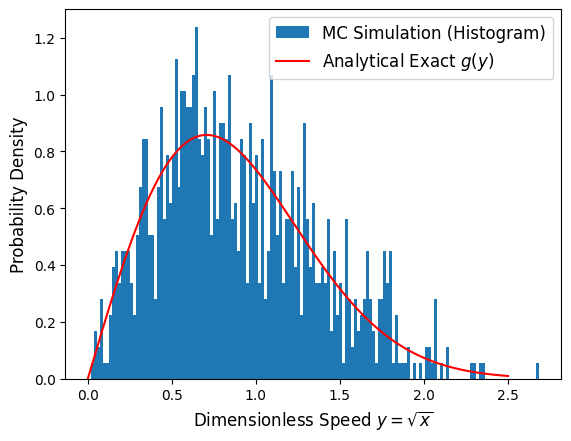

In [14]:
# 4. Visualization

# Plot the normalized histogram of y_samples
plt.hist(y_samples, bins=150, density=True,
         label='MC Simulation (Histogram)')

# Define and plot the analytical PDF g(y)
y_fine = np.linspace(0, 2.5, 1000)
pdf_analytical = 2 * y_fine * np.exp(-y_fine**2)
plt.plot(y_fine, pdf_analytical, color='red',
         label='Analytical Exact $g(y)$')

plt.xlabel(r'Dimensionless Speed $y = \sqrt{x}$', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend(fontsize=12)
plt.show()
#@title { vertical-output: true}

## Part 3: Discussion

**Conclusion:**
The Monte Carlo numerical estimates show excellent agreement with the exact analytical derivations. The slight differences are due to statistical fluctuations inherent to random sampling.